# Task 3: Monthly Spending Prediction EDA

Regression analysis of future 30-day spending (`spending_30d`) in THB.

**Scope:** exploratory analysis only. No models are trained, evaluated, or tuned.

## 1. Dataset Loading

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
SEED = 342
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid', context='notebook')

# This notebook is stored in notebook/, so the data path remains portable.
DATA_ROOT = Path('../../cpe342-kaggle-main')

def quality_report(frame, id_col='player_id'):
    numeric = frame.select_dtypes(include=np.number)
    missing = pd.DataFrame({
        'missing_count': frame.isna().sum(),
        'missing_pct': frame.isna().mean().mul(100)
    }).sort_values('missing_count', ascending=False)
    print(f'Duplicate rows: {frame.duplicated().sum():,}')
    print(f'Duplicate {id_col}s: {frame[id_col].duplicated().sum():,}')
    print(f'Infinite numeric values: {np.isinf(numeric).sum().sum():,}')
    display(missing.query('missing_count > 0'))
    constants = frame.columns[frame.nunique(dropna=False).le(1)].tolist()
    near_constant = (frame.nunique(dropna=False) / len(frame)).sort_values().head(10)
    print('Constant features:', constants or 'None')
    display(near_constant.to_frame('unique_ratio'))
    return missing

def plot_missing(missing, title):
    shown = missing.query('missing_count > 0').head(25)
    if shown.empty:
        print('No missing values to plot.')
        return
    fig, ax = plt.subplots(figsize=(10, max(3, len(shown) * .3)))
    sns.barplot(data=shown.reset_index(), y='index', x='missing_pct', ax=ax, color='#4C72B0')
    ax.set(title=title, xlabel='Missing values (%)', ylabel='Column')
    plt.show(); plt.close()

def strong_correlations(frame, threshold=.75):
    corr = frame.select_dtypes(include=np.number).corr()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    pairs = upper.stack().rename('correlation').reset_index()
    return pairs.loc[pairs.correlation.abs().ge(threshold)].sort_values('correlation', key=np.abs, ascending=False)


In [2]:
train = pd.read_csv(DATA_ROOT / '03_regression/train.csv')
print('Train shape:', train.shape)
print(f'Memory usage: {train.memory_usage(deep=True).sum()/1024**2:.2f} MiB')
display(train.head())
display(train.dtypes.rename('dtype').to_frame())
display(train.describe(include='all').T)
display(train.nunique(dropna=False).rename('unique_values').to_frame().sort_values('unique_values'))

test = pd.read_csv(DATA_ROOT / '03_regression/test.csv')
print('Test shape:', test.shape)
print('Columns differing from train:', sorted(set(train.columns).symmetric_difference(test.columns)))
display(pd.DataFrame({'train_missing_pct': train.isna().mean().mul(100), 'test_missing_pct': test.isna().mean().mul(100)}).query('train_missing_pct > 0 or test_missing_pct > 0'))


Train shape: (104000, 34)
Memory usage: 27.67 MiB


,player_id,friend_count,social_interactions,guild_membership,event_participation_rate,daily_login_streak,avg_session_length,sessions_per_week,total_playtime_hours,days_since_last_login,achievement_count,achievement_completion_rate,historical_spending,prev_month_spending,total_transactions,avg_transaction_value,account_age_days,vip_status,is_premium_member,primary_game,games_played,cross_game_activity,platform,days_since_last_purchase,purchase_frequency,payment_methods_used,purchases_on_discount,discount_rate_used,seasonal_spending_pattern,owns_limited_edition,competitive_rank,tournament_participation,segment,spending_30d
0,P015192,178.0,96.0,0.0,35.268732,80.0,NaN,7.764709,780.113032,NaN,240.0,84.500810,NaN,1704.436163,25.0,NaN,329.0,1.0,0.0,3.0,1.0,10.0,0.0,5.299481,11.384819,NaN,9.0,0.360000,9.0,NaN,3.0,0.0,2.0,0.00
1,P111618,191.0,114.0,1.0,35.225308,67.0,130.116951,29.413024,403.615696,11.832143,220.0,71.657519,NaN,843.941233,44.0,62.018316,685.0,1.0,0.0,3.0,NaN,5.0,1.0,9.997526,11.810861,1.0,22.0,0.500000,1.0,0.0,8.0,0.0,1.0,0.00
2,P053928,221.0,137.0,0.0,37.170735,16.0,24.383195,26.243534,694.607894,14.069624,170.0,70.036282,2496.012833,858.091754,22.0,113.455129,218.0,1.0,0.0,2.0,2.0,21.0,0.0,6.249944,19.808857,2.0,12.0,0.545455,NaN,0.0,6.0,1.0,1.0,1837.52
3,P120339,235.0,61.0,0.0,55.991803,50.0,163.692017,7.678702,NaN,4.584786,322.0,47.635144,8311.973813,2749.775284,18.0,461.776323,871.0,1.0,0.0,1.0,2.0,NaN,1.0,50.214706,2.111356,1.0,7.0,0.388889,3.0,0.0,6.0,0.0,2.0,0.00
4,P003004,24.0,86.0,1.0,11.119486,7.0,27.009295,2.459212,508.197429,14.110722,274.0,72.780995,1276.189317,382.757766,46.0,27.743246,1203.0,1.0,0.0,3.0,1.0,7.0,1.0,73.325809,7.920881,2.0,18.0,0.391304,NaN,0.0,5.0,0.0,0.0,0.00


,dtype
player_id,str
friend_count,float64
social_interactions,float64
guild_membership,float64
event_participation_rate,float64
daily_login_streak,float64
avg_session_length,float64
sessions_per_week,float64
total_playtime_hours,float64
days_since_last_login,float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
player_id,104000,104000,P015192,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
friend_count,97917.0,NaN,NaN,NaN,110.413544,65.389766,0.0,59.0,106.0,155.0,410.0
social_interactions,97956.0,NaN,NaN,NaN,65.748744,37.824022,0.0,36.0,64.0,92.0,230.0
guild_membership,97928.0,NaN,NaN,NaN,0.600216,0.489856,0.0,0.0,1.0,1.0,1.0
event_participation_rate,97971.0,NaN,NaN,NaN,39.648077,18.500116,10.001794,25.428284,36.244683,53.064511,84.999814
daily_login_streak,97893.0,NaN,NaN,NaN,56.568478,35.716914,0.0,28.0,53.0,81.0,256.0
avg_session_length,97997.0,NaN,NaN,NaN,110.238653,54.751374,20.000851,66.851791,105.900739,147.31011,364.428629
sessions_per_week,97869.0,NaN,NaN,NaN,14.262752,7.594238,1.000309,8.375196,13.866407,19.463679,47.801941
total_playtime_hours,97954.0,NaN,NaN,NaN,594.562737,292.895858,50.011704,374.381781,583.254682,794.382249,1980.980365
days_since_last_login,97965.0,NaN,NaN,NaN,7.345478,5.454145,0.000012,2.988421,6.247689,10.607699,40.914764


,unique_values
guild_membership,3
tournament_participation,3
is_premium_member,3
owns_limited_edition,3
platform,4
segment,5
games_played,6
payment_methods_used,6
primary_game,6
vip_status,7


Test shape: (25889, 33)
Columns differing from train: ['spending_30d']


,train_missing_pct,test_missing_pct
account_age_days,5.780769,5.658774
achievement_completion_rate,5.851923,5.940747
achievement_count,5.950000,5.824868
avg_session_length,5.772115,5.535169
avg_transaction_value,5.760577,6.060489
competitive_rank,5.711538,5.882807
cross_game_activity,5.922115,5.933022
daily_login_streak,5.872115,5.905983
days_since_last_login,5.802885,5.909846
days_since_last_purchase,5.911538,5.778516


## 2. Dataset Overview

`player_id` is an identifier and should be excluded from future feature matrices unless a justified, leakage-safe use is established.

## 3. Data Quality Assessment

Duplicate rows: 0
Duplicate player_ids: 0
Infinite numeric values: 0


,missing_count,missing_pct
vip_status,6189,5.950962
achievement_count,6188,5.950000
cross_game_activity,6159,5.922115
days_since_last_purchase,6148,5.911538
sessions_per_week,6131,5.895192
platform,6125,5.889423
daily_login_streak,6107,5.872115
discount_rate_used,6103,5.868269
achievement_completion_rate,6086,5.851923
purchases_on_discount,6083,5.849038


Constant features: None


,unique_ratio
guild_membership,0.000029
tournament_participation,0.000029
is_premium_member,0.000029
owns_limited_edition,0.000029
platform,0.000038
segment,0.000048
games_played,0.000058
payment_methods_used,0.000058
primary_game,0.000058
vip_status,0.000067


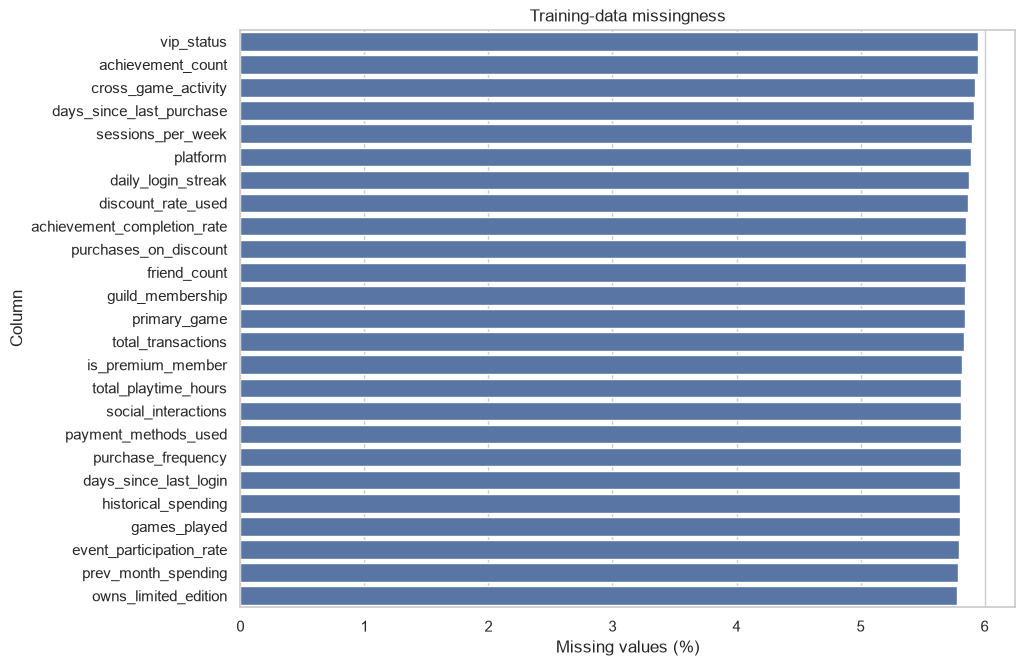

,min,1%,5%,50%,95%,99%,max
friend_count,0.000000,2.000000,12.000000,106.000000,225.000000,275.000000,410.000000
social_interactions,0.000000,1.000000,8.000000,64.000000,132.000000,160.000000,230.000000
guild_membership,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
event_participation_rate,10.001794,10.624418,13.118192,36.244683,73.545368,82.711276,84.999814
daily_login_streak,0.000000,1.000000,5.000000,53.000000,120.000000,149.000000,256.000000
avg_session_length,20.000851,21.914693,30.063307,105.900739,206.853995,250.411313,364.428629
sessions_per_week,1.000309,1.338215,2.691528,13.866407,27.500925,33.169452,47.801941
total_playtime_hours,50.011704,66.975136,132.312149,583.254682,1096.360458,1312.505436,1980.980365
days_since_last_login,0.000012,0.119852,0.609324,6.247689,17.834096,23.093038,40.914764
achievement_count,0.000000,5.000000,29.000000,159.000000,299.000000,357.000000,507.000000


In [3]:
missing = quality_report(train)
plot_missing(missing, 'Training-data missingness')

# Examine numerical extremes without changing the data.
numeric_summary = train.select_dtypes(include=np.number).describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T
display(numeric_summary[['min','1%','5%','50%','95%','99%','max']])

## 4. Target Analysis

,count,percent
spending_30d,,
0.00,50049,48.124038
0.09,1,0.000962
0.12,1,0.000962
0.17,1,0.000962
0.18,2,0.001923
...,...,...
297470.49,1,0.000962
298467.85,1,0.000962
299141.56,1,0.000962


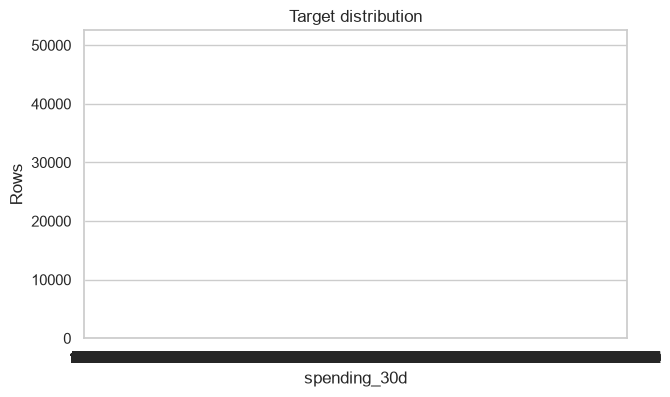

In [4]:
y = train['spending_30d']
positive = y[y > 0]
summary = pd.Series({'rows': len(y), 'zero_count': y.eq(0).sum(), 'zero_pct': y.eq(0).mean()*100, 'positive_count': positive.size, 'positive_pct': positive.size/len(y)*100, 'mean': y.mean(), 'median': y.median(), 'p90': y.quantile(.90), 'p95': y.quantile(.95), 'p99': y.quantile(.99), 'max': y.max(), 'skewness': y.skew()})
display(summary.to_frame('spending_30d'))
fig, axes = plt.subplots(1, 2, figsize=(14,4))
sns.boxplot(x=y, showfliers=False, ax=axes[0]); axes[0].set(title='spending_30d boxplot; outliers hidden', xlabel='THB')
sns.histplot(positive, bins=80, ax=axes[1]); axes[1].set(title='Positive spending only', xlabel='THB')
plt.tight_layout(); plt.show(); plt.close()


## 5. Feature Distribution Analysis

Zero-spending players: 48.12%


,spending_30d
count,104000.000000
mean,10497.040585
std,30568.961446
min,0.000000
1%,0.000000
5%,0.000000
10%,0.000000
25%,0.000000
50%,79.435000
75%,2461.140000


Original-target skewness: 4.170


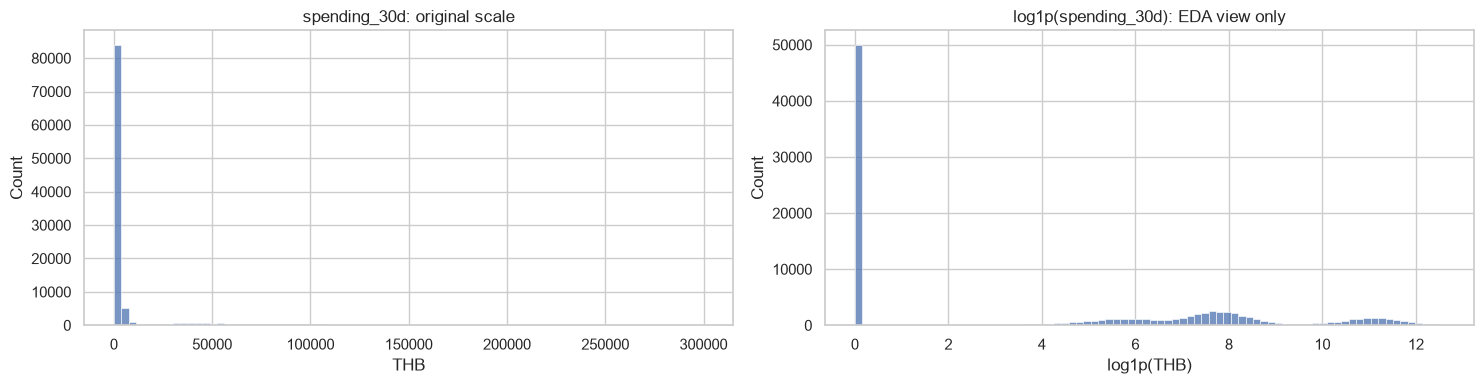

Positive-spending skewness: 2.846452294169521


In [5]:
feature_cols = [c for c in train.columns if c not in ['player_id','spending_30d']]
y = train['spending_30d']
print(f'Zero-spending players: {(y.eq(0).mean()*100):.2f}%')
display(y.describe(percentiles=[.01,.05,.1,.25,.5,.75,.9,.95,.99]).to_frame('spending_30d'))
print(f'Original-target skewness: {y.skew():.3f}')
fig, axes = plt.subplots(1,2,figsize=(15,4))
sns.histplot(y, bins=80, ax=axes[0]); axes[0].set(title='spending_30d: original scale', xlabel='THB')
sns.histplot(np.log1p(y), bins=80, ax=axes[1]); axes[1].set(title='log1p(spending_30d): EDA view only', xlabel='log1p(THB)')
plt.tight_layout(); plt.show(); plt.close()
positive = y[y>0]
print('Positive-spending skewness:', positive.skew())

## 6. Feature Relationships

,correlation_with_spending_30d
historical_spending,0.867378
prev_month_spending,0.865319
segment,0.567305
event_participation_rate,0.497777
vip_status,0.443448
is_premium_member,0.413554
total_transactions,0.284200
avg_transaction_value,0.265900
purchases_on_discount,0.245939
owns_limited_edition,0.201004


,level_0,level_1,correlation
364,historical_spending,prev_month_spending,0.995375
127,event_participation_rate,segment,0.879697
441,total_transactions,purchases_on_discount,0.873951
529,vip_status,is_premium_member,0.805721


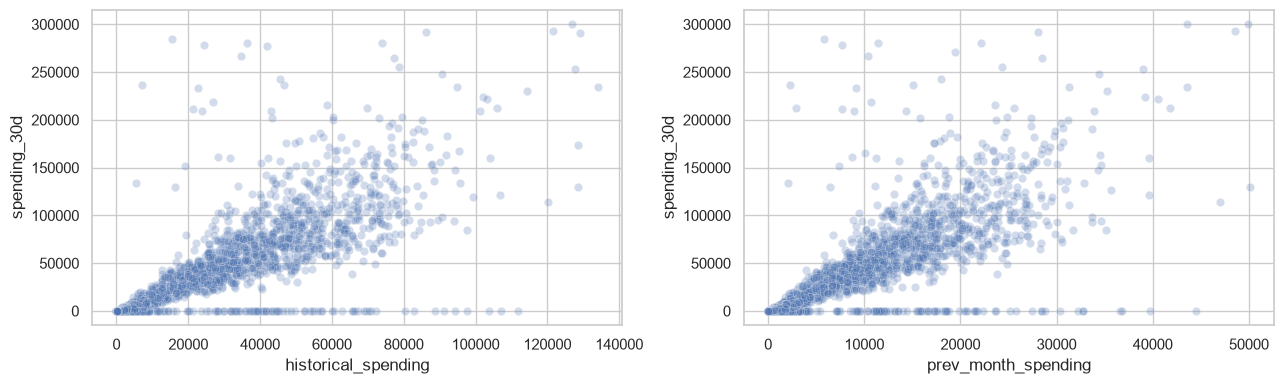

In [6]:
numeric = train.select_dtypes(include=np.number)
corr_target = numeric.corrwith(train['spending_30d']).drop('spending_30d').sort_values(key=np.abs, ascending=False)
display(corr_target.head(15).rename('correlation_with_spending_30d').to_frame())
display(strong_correlations(train[feature_cols]))
fig, axes = plt.subplots(1,2,figsize=(13,4))
sns.scatterplot(data=train.sample(min(10000,len(train)), random_state=SEED), x='historical_spending', y='spending_30d', alpha=.25, ax=axes[0])
sns.scatterplot(data=train.sample(min(10000,len(train)), random_state=SEED), x='prev_month_spending', y='spending_30d', alpha=.25, ax=axes[1])
plt.tight_layout(); plt.show(); plt.close()

## 7. Task-Specific Analysis

In [7]:
print('Zero-spending rate:', round(train.spending_30d.eq(0).mean()*100, 2), '%')
print('Review availability time for historical_spending, prev_month_spending, transactions, and segment to rule out post-outcome leakage.')
print('If the zero mass and positive-value distribution both remain substantial, a future two-stage approach (spend/no spend, then amount) is a hypothesis worth validating with proper cross-validation. No target is transformed or model is fitted here.')

Zero-spending rate: 48.12 %
Review availability time for historical_spending, prev_month_spending, transactions, and segment to rule out post-outcome leakage.
If the zero mass and positive-value distribution both remain substantial, a future two-stage approach (spend/no spend, then amount) is a hypothesis worth validating with proper cross-validation. No target is transformed or model is fitted here.


## 8. EDA Summary & Recommendations

### Key findings

- The data has 104,000 rows and 34 columns, with no duplicate rows or duplicate player_id values.
- spending_30d is zero for 50,041 players (48.12%); 53,959 players (51.88%) have positive spending.
- The target mean is THB 10,497.04 and median is THB 79.44. The 99th percentile is THB 150,032.30 and skewness is 4.17, showing a strongly right-skewed, zero-inflated distribution.
- vip_status has 6,189 missing values, achievement_count 6,188, and cross_game_activity 6,159.
- The notebook uses histograms, positive-only distributions, quantiles, and log1p visualisation; it no longer uses categorical target counting for this continuous variable.

### Leakage and recommendations

Audit the timing of historical_spending, prev_month_spending, transaction fields, and segment: each is appropriate only if available before the next 30-day outcome window. A future two-stage spend/no-spend then amount approach is a testable hypothesis given the 48.12% zero rate. Preserve the original target for NMAE scoring. No regression model is fitted.
